In [ ]:

!pip install kagglehub matplotlib seaborn numpy pandas opencv-python tensorflow scikit-learn


import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
import os
import glob
from PIL import Image
import warnings
warnings.filterwarnings('ignore')


plt.style.use('default')
sns.set_palette("husl")

In [ ]:
# Preuzmi dataset koristeći kagglehub
path = kagglehub.dataset_download("msambare/fer2013")
print("Path to dataset files:", path)


print("\nStruktura dataset-a:")
for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    subindent = ' ' * 2 * (level + 1)
    for file in files[:5]:
        print(f"{subindent}{file}")
    if len(files) > 5:
        print(f"{subindent}... i još {len(files)-5} datoteka")

train_path = os.path.join(path, 'train')
test_path = os.path.join(path, 'test')

print(f"\nTrain mapa: {train_path}")
print(f"Test mapa: {test_path}")
print(f"Train mapa postoji: {os.path.exists(train_path)}")
print(f"Test mapa postoji: {os.path.exists(test_path)}")

Path to dataset files: /kaggle/input/fer2013

Struktura dataset-a:
fer2013/
  test/
    surprise/
      PublicTest_78686873.jpg
      PrivateTest_58522921.jpg
      PrivateTest_83796714.jpg
      PublicTest_84428313.jpg
      PrivateTest_87978901.jpg
      ... i još 826 datoteka
    fear/
      PublicTest_67261410.jpg
      PrivateTest_80486885.jpg
      PrivateTest_29930852.jpg
      PublicTest_61256129.jpg
      PrivateTest_86063456.jpg
      ... i još 1019 datoteka
    angry/
      PublicTest_3641536.jpg
      PublicTest_21334851.jpg
      PrivateTest_56252993.jpg
      PrivateTest_46881419.jpg
      PrivateTest_88795628.jpg
      ... i još 953 datoteka
    neutral/
      PublicTest_85967214.jpg
      PrivateTest_61407797.jpg
      PublicTest_24698430.jpg
      PrivateTest_50523939.jpg
      PublicTest_54940641.jpg
      ... i još 1228 datoteka
    sad/
      PublicTest_50867484.jpg
      PublicTest_4475358.jpg
      PrivateTest_33171436.jpg
      PublicTest_38685191.jpg
      Priva

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_dir = "/kaggle/input/fer2013/train"
test_dir = "/kaggle/input/fer2013/test"


train_datagen = ImageDataGenerator(
    width_shift_range = 0.1,
    height_shift_range = 0.1,
    horizontal_flip = True,
    rescale = 1./255,
    validation_split = 0.2
)

validation_datagen = ImageDataGenerator(
    rescale = 1./255,
    validation_split = 0.2
)

train_generator = train_datagen.flow_from_directory(
    directory = train_dir,
    target_size = (48, 48),
    batch_size = 64,
    color_mode = "grayscale",
    class_mode = "categorical",
    subset = "training"
)

validation_generator = validation_datagen.flow_from_directory(
    directory = test_dir,
    target_size = (48, 48),
    batch_size = 64,
    color_mode = "grayscale",
    class_mode = "categorical",
    subset = "validation"
)

Found 22968 images belonging to 7 classes.
Found 1432 images belonging to 7 classes.


In [ ]:
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.models import Sequential
import tensorflow as tf
from tensorflow.keras.layers import BatchNormalization


model = Sequential()

# Add a convolutional layer with 32 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(48,48,1)))
# Add a batch normalization layer
model.add(BatchNormalization())
# Add a second convolutional layer with 64 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
# Add a second batch normalization layer
model.add(BatchNormalization())
# Add a max pooling layer with 2x2 pool size
model.add(MaxPooling2D(pool_size=(2, 2)))
# Add a dropout layer with 0.25 dropout rate
model.add(Dropout(0.25))

# Add a third convolutional layer with 128 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
# Add a third batch normalization layer
model.add(BatchNormalization())
# Add a fourth convolutional layer with 128 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
# Add a fourth batch normalization layer
model.add(BatchNormalization())
# Add a max pooling layer with 2x2 pool size
model.add(MaxPooling2D(pool_size=(2, 2)))
# Add a dropout layer with 0.25 dropout rate
model.add(Dropout(0.25))

# Add a fifth convolutional layer with 256 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(256, kernel_size=(3, 3), activation='relu'))
# Add a fifth batch normalization layer
model.add(BatchNormalization())
# Add a sixth convolutional layer with 256 filters, 3x3 kernel size, and relu activation function
model.add(Conv2D(256, kernel_size=(3, 3), activation='relu'))
# Add a sixth batch normalization layer
model.add(BatchNormalization())
# Add a max pooling layer with 2x2 pool size
model.add(MaxPooling2D(pool_size=(2, 2)))
# Add a dropout layer with 0.25 dropout rate
model.add(Dropout(0.25))

# Flatten the output of the convolutional layers
model.add(Flatten())
# Add a dense layer with 256 neurons and relu activation function
model.add(Dense(256, activation='relu'))
# Add a seventh batch normalization layer
model.add(BatchNormalization())
# Add a dropout layer with 0.5 dropout rate
model.add(Dropout(0.5))
# Add a dense layer with 7 neurons (one for each class) and softmax activation function
model.add(Dense(7, activation='softmax'))

# Compile the model with categorical cross-entropy loss, adam optimizer, and accuracy metric
model.compile(loss="categorical_crossentropy",
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              metrics=['accuracy'])

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 46, 46, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 44, 44, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 44, 44, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 18, 18, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 7, 7, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 7, 7, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 5, 5, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 5, 5, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,394,183 (5.32 MB)

 Trainable params: 1,391,943 (5.31 MB)

 Non-trainable params: 2,240 (8.75 KB)

In [12]:
Žr
om tensorflow.keras.callbacks import ModelCheckpoint


checkpoint_callback = ModelCheckpoint(
    filepath='model.weights.h5',
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,
    mode='max',
    verbose=1
)


history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=50,
    validation_data=validation_generator,
    validation_steps=len(validation_generator),
    callbacks=[checkpoint_callback]
)

Epoch 1/50
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.1624 - loss: 2.9507
Epoch 1: val_accuracy improved from -inf to 0.21299, saving model to model.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 584s 2s/step - accuracy: 0.1625 - loss: 2.9502 - val_accuracy: 0.2130 - val_loss: 1.8888
Epoch 2/50
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2160 - loss: 2.4268
Epoch 2: val_accuracy improved from 0.21299 to 0.34637, saving model to model.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 616s 2s/step - accuracy: 0.2160 - loss: 2.4267 - val_accuracy: 0.3464 - val_loss: 1.7181
Epoch 3/50
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2497 - loss: 2.2382
Epoch 3: val_accuracy improved from 0.34637 to 0.35824, saving model to model.weights.h5
359/359 ━━━━━━━━━━━━━━━━━━━━ 613s 2s/step - accuracy: 0.2498 - loss: 2.2380 - val_accuracy: 0.3582 - val_loss: 1.6831
Epoch 4/50
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2866 - loss: 2.0760
Epoch 4: val_accuracy did not improve from

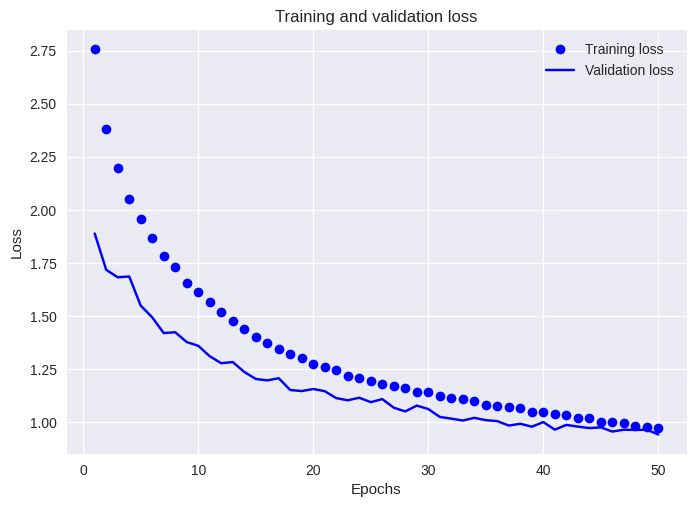

In [15]:
# Plot the train and validation loss
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(train_loss) + 1)
plt.plot(epochs, train_loss, 'bo', label='Training loss')
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

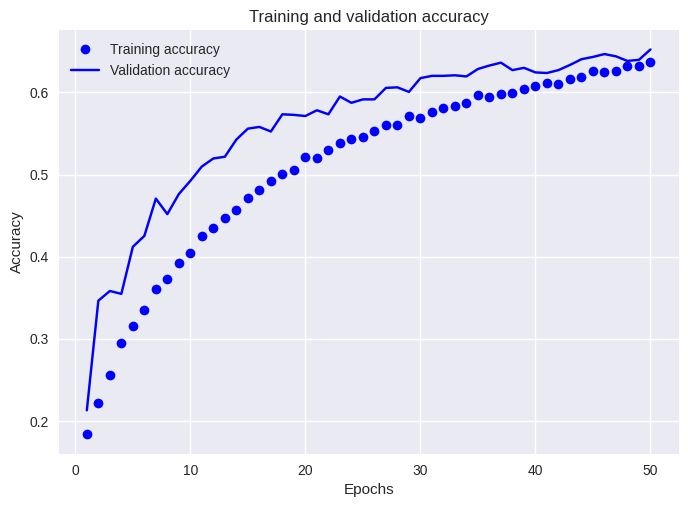

In [16]:
# Plot the train and validation accuracy
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
plt.plot(epochs, train_acc, 'bo', label='Training accuracy')
plt.plot(epochs, val_acc, 'b', label='Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

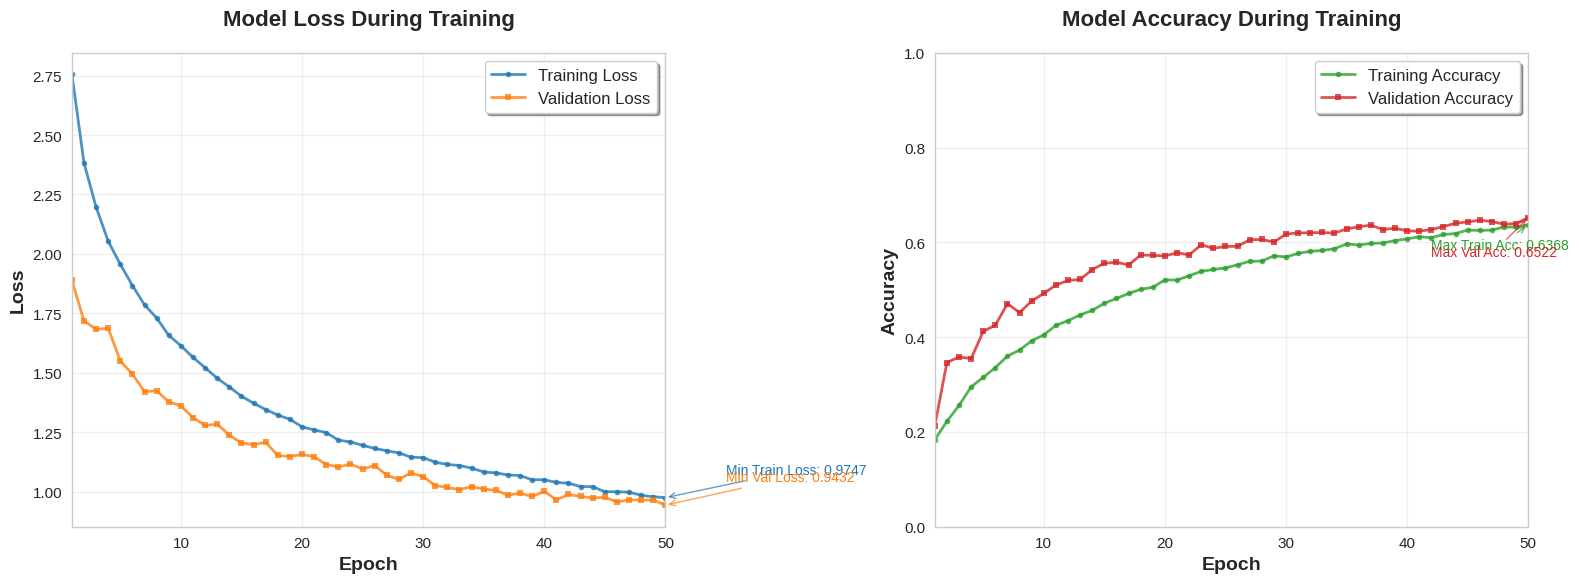

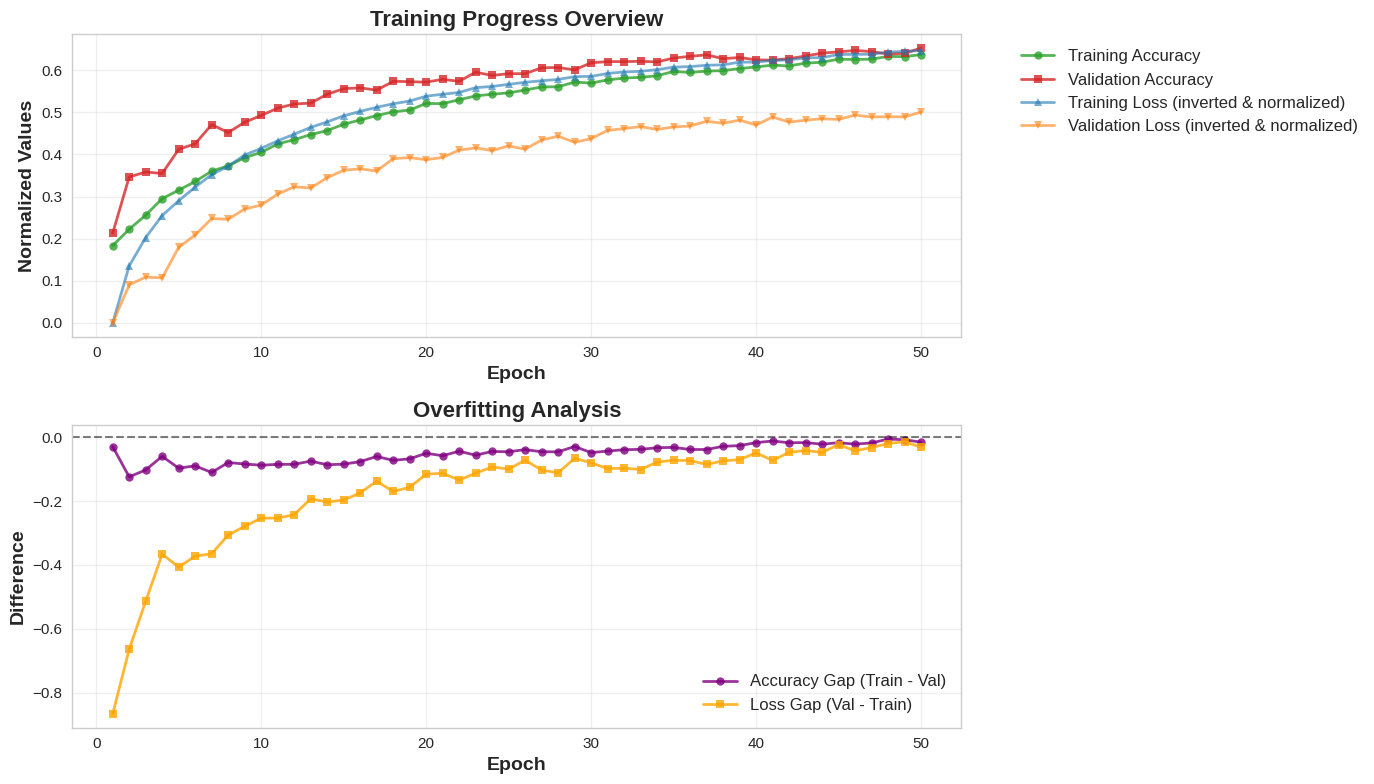

SAŽETAK TRENIRANJA
Ukupno epoha: 50
Finalna training accuracy: 0.6368 (63.68%)
Finalna validation accuracy: 0.6522 (65.22%)
Najbolja validation accuracy: 0.6522 (65.22%) u epohi 50
Finalni training loss: 0.9747
Finalni validation loss: 0.9432
Najmanji validation loss: 0.9432 u epohi 50


In [18]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Postavke za lijepe grafove
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (15, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['legend.fontsize'] = 12

# Podaci za grafove
train_loss = history.history['loss']
val_loss = history.history['val_loss']
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(1, len(train_loss) + 1)

# Kreiraj subplot s 2 grafa
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Graf 1: Loss
ax1.plot(epochs, train_loss, 'o-', color='#1f77b4', linewidth=2, markersize=4,
         label='Training Loss', alpha=0.8)
ax1.plot(epochs, val_loss, 's-', color='#ff7f0e', linewidth=2, markersize=4,
         label='Validation Loss', alpha=0.8)

ax1.set_title('Model Loss During Training', fontweight='bold', pad=20)
ax1.set_xlabel('Epoch', fontweight='bold')
ax1.set_ylabel('Loss', fontweight='bold')
ax1.legend(frameon=True, fancybox=True, shadow=True)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(1, len(epochs))

# Dodaj min vrijednosti
min_train_loss = min(train_loss)
min_val_loss = min(val_loss)
min_train_epoch = train_loss.index(min_train_loss) + 1
min_val_epoch = val_loss.index(min_val_loss) + 1

ax1.annotate(f'Min Train Loss: {min_train_loss:.4f}',
             xy=(min_train_epoch, min_train_loss),
             xytext=(min_train_epoch + 5, min_train_loss + 0.1),
             arrowprops=dict(arrowstyle='->', color='#1f77b4', alpha=0.7),
             fontsize=10, color='#1f77b4')

ax1.annotate(f'Min Val Loss: {min_val_loss:.4f}',
             xy=(min_val_epoch, min_val_loss),
             xytext=(min_val_epoch + 5, min_val_loss + 0.1),
             arrowprops=dict(arrowstyle='->', color='#ff7f0e', alpha=0.7),
             fontsize=10, color='#ff7f0e')

# Graf 2: Accuracy
ax2.plot(epochs, train_acc, 'o-', color='#2ca02c', linewidth=2, markersize=4,
         label='Training Accuracy', alpha=0.8)
ax2.plot(epochs, val_acc, 's-', color='#d62728', linewidth=2, markersize=4,
         label='Validation Accuracy', alpha=0.8)

ax2.set_title('Model Accuracy During Training', fontweight='bold', pad=20)
ax2.set_xlabel('Epoch', fontweight='bold')
ax2.set_ylabel('Accuracy', fontweight='bold')
ax2.legend(frameon=True, fancybox=True, shadow=True)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(1, len(epochs))
ax2.set_ylim(0, 1)

# Dodaj max vrijednosti
max_train_acc = max(train_acc)
max_val_acc = max(val_acc)
max_train_epoch = train_acc.index(max_train_acc) + 1
max_val_epoch = val_acc.index(max_val_acc) + 1

ax2.annotate(f'Max Train Acc: {max_train_acc:.4f}',
             xy=(max_train_epoch, max_train_acc),
             xytext=(max_train_epoch - 8, max_train_acc - 0.05),
             arrowprops=dict(arrowstyle='->', color='#2ca02c', alpha=0.7),
             fontsize=10, color='#2ca02c')

ax2.annotate(f'Max Val Acc: {max_val_acc:.4f}',
             xy=(max_val_epoch, max_val_acc),
             xytext=(max_val_epoch - 8, max_val_acc - 0.08),
             arrowprops=dict(arrowstyle='->', color='#d62728', alpha=0.7),
             fontsize=10, color='#d62728')

plt.tight_layout()
plt.show()

# Dodatni graf - kombiniran prikaz
plt.figure(figsize=(14, 8))

# Subplot 1: Loss i Accuracy na istom grafu (normalizirano)
plt.subplot(2, 1, 1)
# Normaliziraj loss za prikaz s accuracy
train_loss_norm = np.array(train_loss) / max(train_loss)
val_loss_norm = np.array(val_loss) / max(val_loss)

plt.plot(epochs, train_acc, 'o-', color='#2ca02c', linewidth=2,
         label='Training Accuracy', alpha=0.8)
plt.plot(epochs, val_acc, 's-', color='#d62728', linewidth=2,
         label='Validation Accuracy', alpha=0.8)
plt.plot(epochs, 1 - train_loss_norm, '^-', color='#1f77b4', linewidth=2,
         label='Training Loss (inverted & normalized)', alpha=0.6)
plt.plot(epochs, 1 - val_loss_norm, 'v-', color='#ff7f0e', linewidth=2,
         label='Validation Loss (inverted & normalized)', alpha=0.6)

plt.title('Training Progress Overview', fontweight='bold', fontsize=16)
plt.xlabel('Epoch', fontweight='bold')
plt.ylabel('Normalized Values', fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)

# Subplot 2: Razlika između train i validation
plt.subplot(2, 1, 2)
acc_diff = np.array(train_acc) - np.array(val_acc)
loss_diff = np.array(val_loss) - np.array(train_loss)

plt.plot(epochs, acc_diff, 'o-', color='purple', linewidth=2,
         label='Accuracy Gap (Train - Val)', alpha=0.8)
plt.plot(epochs, loss_diff, 's-', color='orange', linewidth=2,
         label='Loss Gap (Val - Train)', alpha=0.8)
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)

plt.title('Overfitting Analysis', fontweight='bold', fontsize=16)
plt.xlabel('Epoch', fontweight='bold')
plt.ylabel('Difference', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Sažetak rezultata u tablici
print("="*60)
print("SAŽETAK TRENIRANJA")
print("="*60)
print(f"Ukupno epoha: {len(epochs)}")
print(f"Finalna training accuracy: {train_acc[-1]:.4f} ({train_acc[-1]*100:.2f}%)")
print(f"Finalna validation accuracy: {val_acc[-1]:.4f} ({val_acc[-1]*100:.2f}%)")
print(f"Najbolja validation accuracy: {max_val_acc:.4f} ({max_val_acc*100:.2f}%) u epohi {max_val_epoch}")
print(f"Finalni training loss: {train_loss[-1]:.4f}")
print(f"Finalni validation loss: {val_loss[-1]:.4f}")
print(f"Najmanji validation loss: {min_val_loss:.4f} u epohi {min_val_epoch}")
print("="*60)


23/23 ━━━━━━━━━━━━━━━━━━━━ 11s 407ms/step


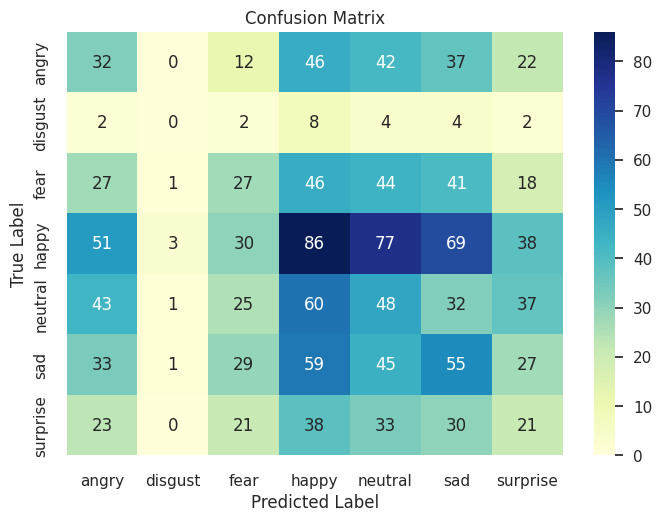

In [17]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Get the true labels and predicted labels for the validation set
validation_labels = validation_generator.classes
validation_pred_probs = model.predict(validation_generator)
validation_pred_labels = np.argmax(validation_pred_probs, axis=1)

# Compute the confusion matrix
confusion_mtx = confusion_matrix(validation_labels, validation_pred_labels)
class_names = list(train_generator.class_indices.keys())
sns.set()
sns.heatmap(confusion_mtx, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [3]:
import os

# Provjeri da li postoji sačuvan model
if os.path.exists('model.weights.h5'):
    print("Model postoji - možete ga učitati")
    model = tf.keras.models.load_model('model.weights.h5')
else:
    print("Model ne postoji - morate ponovno trenirati")

Model ne postoji - morate ponovno trenirati
